In [11]:
'''

Exploratory Data Analysis for all Data Roles
Roles to Explore

'''
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt  

# Loading Data
df = pd.read_csv(r'C:\Users\sunda\OneDrive\Desktop\Python_works\job_postings_flat.csv')



In [13]:
df['job_posted_date'] = pd.to_datetime(df.job_posted_date)
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)



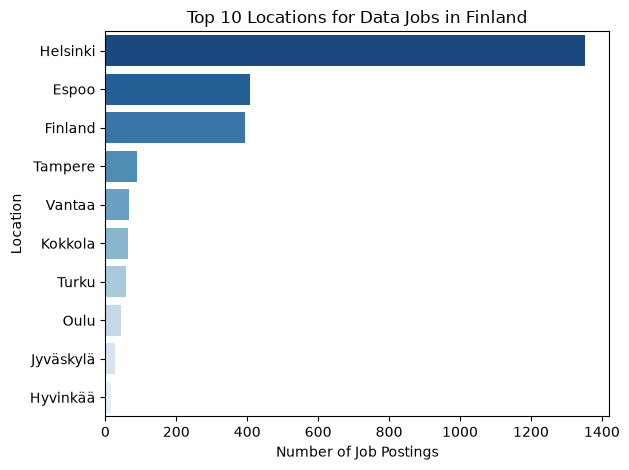

In [14]:
# EDA1
# Filter Finland data jobs
job_titles = ['Data Analyst', 'Data Scientist', 'Data Engineer','Business Analyst']

df_fin = df[
    (df['job_country'] == 'Finland') &
    (df['job_title_short'].isin(job_titles))
].copy()

# Remove Anywhere
df_fin = df_fin[
    ~df_fin['job_location'].str.contains('Anywhere', na=False)
]

# Remove ", Finland" from labels
df_fin['job_location'] = (
    df_fin['job_location']
    .str.replace(', Finland', '', regex=False)
)

# Count jobs
location_counts = (
    df_fin['job_location']
    .value_counts()
    .head(10)
    .reset_index()
)

location_counts.columns = ['job_location', 'job_count']

sns.barplot(
    data=location_counts,
    x='job_count',
    y='job_location',
    palette='Blues_r',
    hue='job_location',
    legend=False
)
plt.title('Top 10 Locations for Data Jobs in Finland')
plt.xlabel('Number of Job Postings')
plt.ylabel('Location')
plt.tight_layout()
plt.show()



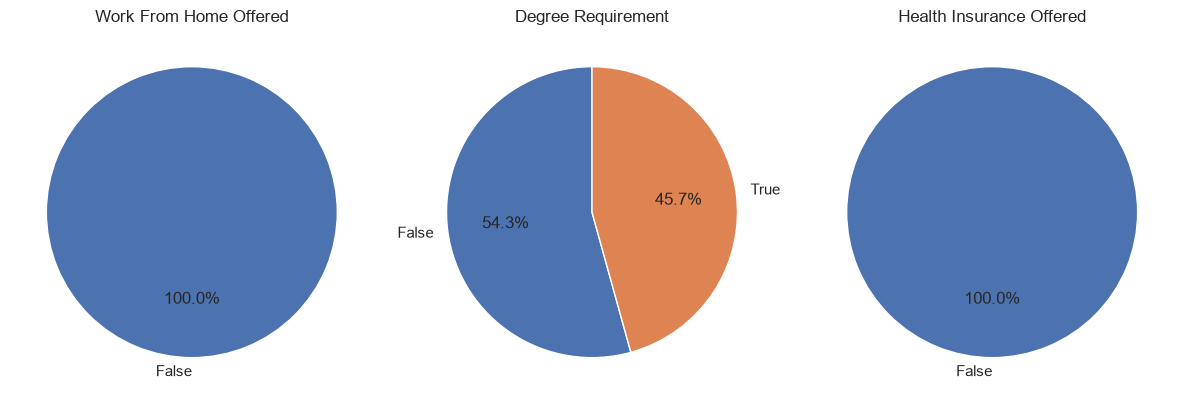

In [37]:
# EDA 2 - Benefits & Requirements Analysis

# Count True and False values
work_from_home = df_fin['job_work_from_home'].value_counts()
job_no_degree = df_fin['job_no_degree_mention'].value_counts()
job_insurance = df_fin['job_health_insurance'].value_counts()

# Create figure
fig, ax = plt.subplots(1, 3, figsize=(12, 5))

# Work From Home
plt.subplot(1, 3, 1)
plt.pie(
    work_from_home,
    labels=work_from_home.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Work From Home Offered')

# No Degree Mention
plt.subplot(1, 3, 2)
plt.pie(
    job_no_degree,
    labels=job_no_degree.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Degree Requirement')

# Health Insurance
plt.subplot(1, 3, 3)
plt.pie(
    job_insurance,
    labels=job_insurance.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Health Insurance Offered')

plt.tight_layout()
plt.show()

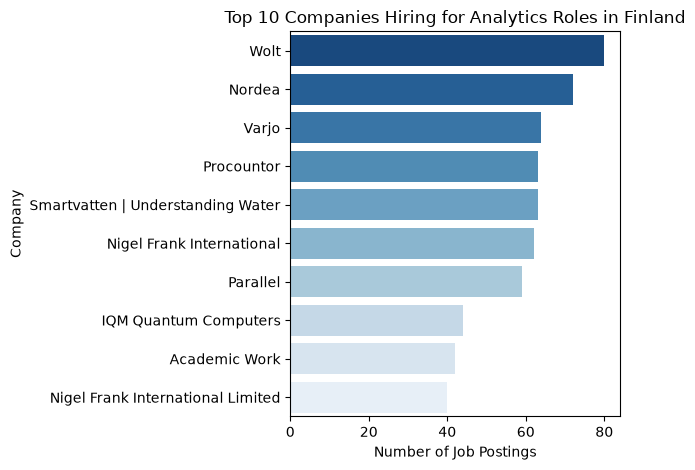

In [15]:
# EDA 3 what are the companies offering this jobs in finland 
# job titles
job_titles = [
    'Data Analyst',
    'Data Scientist',
    'Data Engineer',
    'Business Analyst'
]
# filter for finland jobs
df_fin = df[
    (df['job_country'] == 'Finland') &
    (df['job_title_short'].isin(job_titles))
].copy()

# count companies offering jobs in Finland
company_counts = (
    df_fin['company_name']
    .value_counts()
    .head(10)
    .reset_index()
)

company_counts.columns = ['company_name', 'job_count']
# plot outcome
sns.barplot(
    data=company_counts,
    x='job_count',
    y='company_name',
    palette='Blues_r',
    hue='company_name',
    legend=False
)

plt.title('Top 10 Companies Hiring for Analytics Roles in Finland')
plt.xlabel('Number of Job Postings')
plt.ylabel('Company')

plt.tight_layout()
plt.show()

In [ ]:
# EDA 4 top paying jobs titles and  also top paying companies 

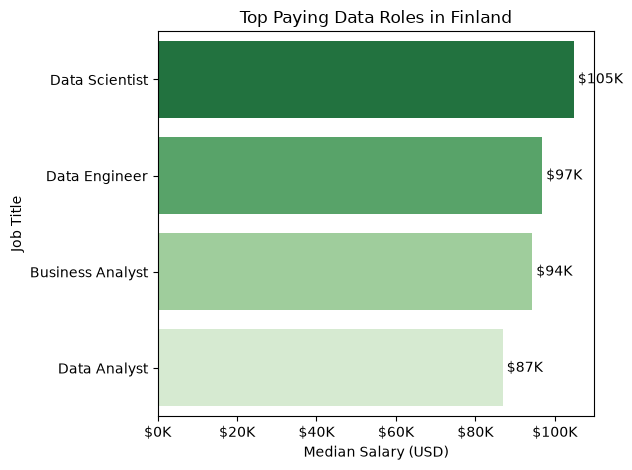

In [17]:
# what are the top job Titles and the median salary
# Job titles to analyze
job_titles = [
    'Data Analyst',
    'Data Scientist',
    'Data Engineer',
    'Business Analyst'
]

# Filter Finland jobs
df_fin = df[
    (df['job_country'] == 'Finland') &
    (df['job_title_short'].isin(job_titles))
].copy()

# get the roles salary
role_salary = (
    df_fin
    .groupby('job_title_short')['salary_year_avg']
    .median()
    .sort_values(ascending=False)
    .reset_index()
)
# plot
from matplotlib.ticker import FuncFormatter

ax = sns.barplot(
    data=role_salary,
    x='salary_year_avg',
    y='job_title_short',
    palette='Greens_r',
    hue='job_title_short',
    legend=False
)

# Add value labels
for container in ax.containers:
    labels = [f'${v/1000:.0f}K' for v in container.datavalues]

    ax.bar_label(
        container,
        labels=labels,
        padding=3
    )

plt.title('Top Paying Data Roles in Finland')
plt.xlabel('Median Salary (USD)')
plt.ylabel('Job Title')

formatter = FuncFormatter(lambda x, pos: f'${x/1000:.0f}K')
plt.gca().xaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

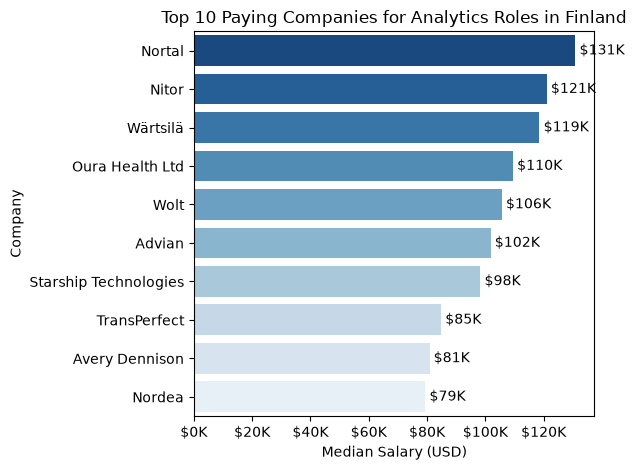

In [18]:
# EDA 5
# top paying companies 
# what are the top job Titles and the median salary
# Job titles to analyze
job_titles = [
    'Data Analyst',
    'Data Scientist',
    'Data Engineer',
    'Business Analyst'
]

# Filter Finland jobs
df_fin = df[
    (df['job_country'] == 'Finland') &
    (df['job_title_short'].isin(job_titles))
].copy()

# get the top paying top 10 companies 
top_companies = (
    df_fin
    .groupby('company_name')['salary_year_avg']
    .median()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
# plot
from matplotlib.ticker import FuncFormatter

ax = sns.barplot(
    data=top_companies,
    x='salary_year_avg',
    y='company_name',
    palette='Blues_r',
    hue='company_name',
    legend=False
)

# Add value labels
for container in ax.containers:
    labels = [f'${v/1000:.0f}K' for v in container.datavalues]

    ax.bar_label(
        container,
        labels=labels,
        padding=3
    )

plt.title('Top 10 Paying Companies for Analytics Roles in Finland')
plt.xlabel('Median Salary (USD)')
plt.ylabel('Company')

formatter = FuncFormatter(lambda x, pos: f'${x/1000:.0f}K')
plt.gca().xaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()